In [ ]:
# CREATE ERROR CSV FILES

from astropy.io import fits
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

nights = [
    "20261116",
    "20260727",
    "20260822",
    "20260731",
    "20260714",
    "20260713",
    "20260719",
    "20260823",
    "20260903",
    "20260604",
]

recent_nights = [
    "20261116",
    "20261115",
    "20261114",
    "20261113",
    "20261112",
    "20261111",
    "20261106",
    "20261105",
    "20261104",
    "20261103",
]

for night in recent_nights:
    columns_headers = {
        "timestamp": [],
        "image_name": [],
        "cycles": [],
        "cycle_idx": [],
        "seqs": [],
        "seq_idx": [],
        "frames": [],
        "frame_idx": [],
        "exptime": [],
        "wppos": [],
        "wpang": [],
        "error": [],
    }
    images_folder = Path(f"E:/images/{night}")
    images = list(images_folder.glob("*.fits"))
    headers = [fits.getheader(image) for image in images]

    for header in headers:
        if header["INSTMODE"] != "POLAR":
            continue
        if header["OBSTYPE"] not in ["OBJECT", "FLAT"]:
            continue
        if header["WPANG"] == "":
            continue
        columns_headers["timestamp"].append(header["DATE-OBS"])
        columns_headers["image_name"].append(header["FILENAME"])
        columns_headers["cycles"].append(header["NCYCLES"])
        columns_headers["cycle_idx"].append(header["CYCLIND"])
        columns_headers["seqs"].append(header["NSEQ"])
        columns_headers["seq_idx"].append(header["SEQINDEX"])
        columns_headers["frames"].append(header["NFRAMES"])
        columns_headers["frame_idx"].append(header["FRAMEIND"])
        columns_headers["exptime"].append(header["EXPTIME"])
        columns_headers["wppos"].append(header["WPPOS"])
        columns_headers["wpang"].append(header["WPANG"])

    for idx, (wppos, wpang) in enumerate(
        zip(columns_headers["wppos"], columns_headers["wpang"])
    ):
        expected_ang = 22.5 * (wppos - 1)
        error = expected_ang - wpang
        columns_headers["error"].append(error)

    df = pd.DataFrame.from_dict(columns_headers)
    df = df[-300 < df["error"]]
    csv_file = Path.cwd() / "_csv" / f"{night}.csv"
    df.to_csv(csv_file)

20261116 & 4.51 & 6.19\\


FileNotFoundError: [Errno 2] No such file or directory: 'c:\\Users\\Denis\\Desktop\\S4CSTP\\notebooks\\wppos_error\\_csv\\20260727.csv'

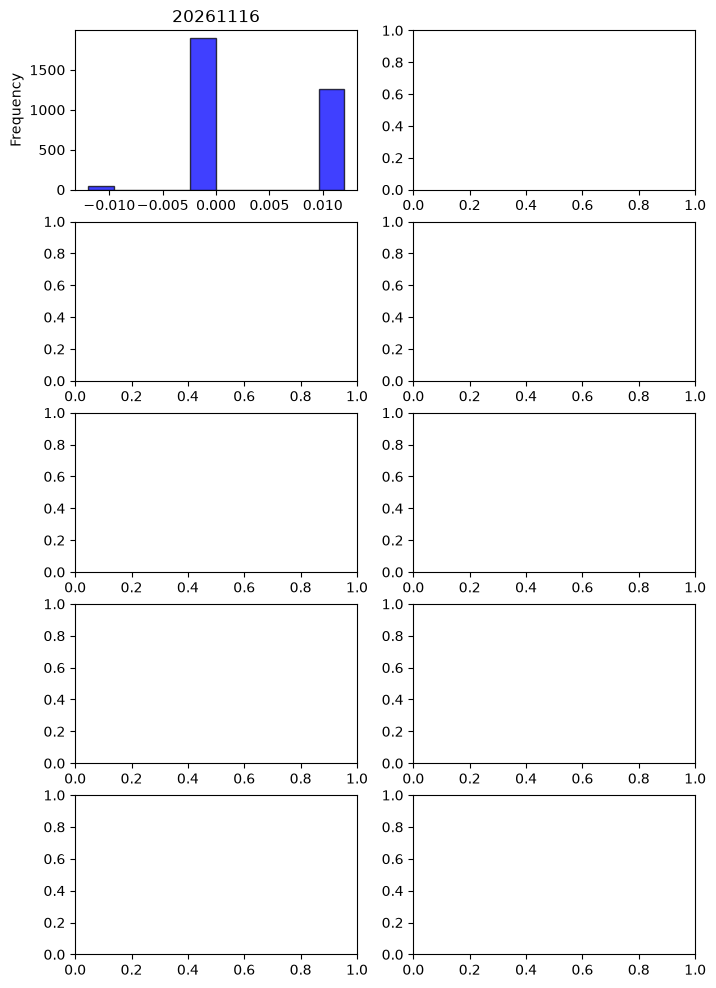

In [8]:
# PLOT HISTOGRAM DISTRIBUTIONS

import numpy as np
from matplotlib import pyplot as plt
import pandas as pd
from pathlib import Path

fig, axs = plt.subplots(5, 2, figsize=(8, 12))
axs = axs.flatten()


nights = [
    "20261116",
    "20260727",
    "20260822",
    "20260731",
    "20260714",
    "20260713",
    "20260719",
    "20260823",
    "20260903",
    "20260604",
]


for idx, night in enumerate(nights):
    ax = axs[idx]
    csv_file = Path.cwd() / "_csv" / f"{night}.csv"
    df = pd.read_csv(csv_file)
    mean = np.mean(df["error"]) * 1e3
    std = np.std(df["error"]) * 1e3
    ax.hist(df["error"], color="blue", edgecolor="black", alpha=0.75)
    ax.set_title(rf"{night}")
    if idx % 2 == 0:
        ax.set_ylabel("Frequency")
    print(
        rf"{night} & {mean:.2f} & {std:.2f}\\",
    )


axs[-1].set_xlabel("Waveplate position error (deg)")
axs[-2].set_xlabel("Waveplate position error (deg)")
plt.tight_layout()
image_path = Path.cwd() / "_figs" / "wppos_error_hist.png"
plt.savefig(image_path, dpi=300, bbox_inches="tight")
image_path = Path(
    r"C:\Users\Denis\Desktop\NT_WPPOS_ERR\src\XX\Fig\recent_error_histograms.png"
)
plt.savefig(image_path, dpi=300, bbox_inches="tight")
plt.show()

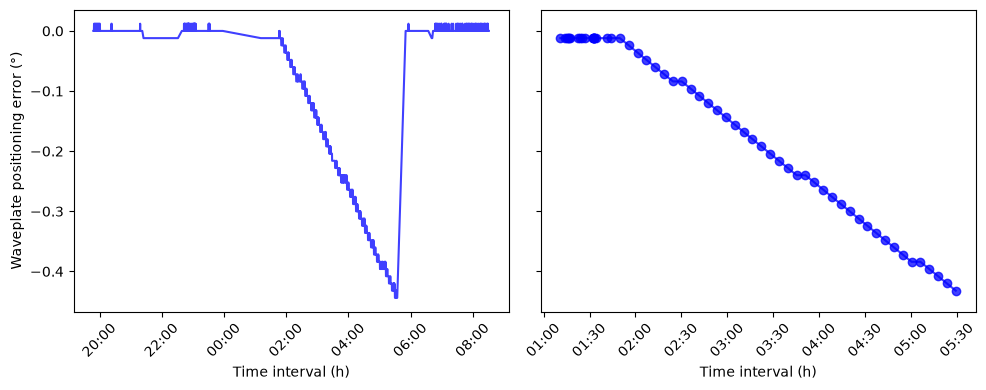

In [6]:
# PLOT THE POSITIONING ERROR VS THE OBSERVATION TIME

import numpy as np
import matplotlib.dates as mdates
from matplotlib import pyplot as plt
import pandas as pd
from pathlib import Path
from datetime import datetime

fig, axs = plt.subplots(1, 2, sharey=True, figsize=(10, 4))

night = "20260702"
csv_file = Path.cwd() / "_csv" / f"{night}.csv"
df = pd.read_csv(csv_file)
mean, std = np.mean(df["error"]), np.std(df["error"])
df["timestamp"] = pd.to_datetime(df["timestamp"], format="%Y-%m-%dT%H:%M:%S.%f")

ax = axs[0]
ax.plot(df["timestamp"], df["error"], "-b", alpha=0.75)
ax.set_ylabel("Waveplate positioning error (°)")
ax.set_xlabel("Time interval (h)")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
ax.tick_params(axis="x", labelrotation=45)

df = df[df["seq_idx"] == 1]
df = df[df["frame_idx"] == 1]
df = df[df["timestamp"] > datetime(2026, 7, 3, 1)]
df = df[df["timestamp"] < datetime(2026, 7, 3, 5, 30)]
ax = axs[1]
ax.plot(df["timestamp"], df["error"], "o-b", alpha=0.75)
ax.set_xlabel("Time interval (h)")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
ax.tick_params(axis="x", labelrotation=45)


image_path = Path.cwd() / "_figs" / f"{night}_err_time_series.png"
plt.savefig(image_path, dpi=300, bbox_inches="tight")
image_path = Path(
    rf"C:\Users\Denis\Desktop\NT_WPPOS_ERR\src\XX\Fig\{night}_err_time_series.png"
)
plt.savefig(image_path, dpi=300, bbox_inches="tight")
plt.tight_layout()
plt.show()

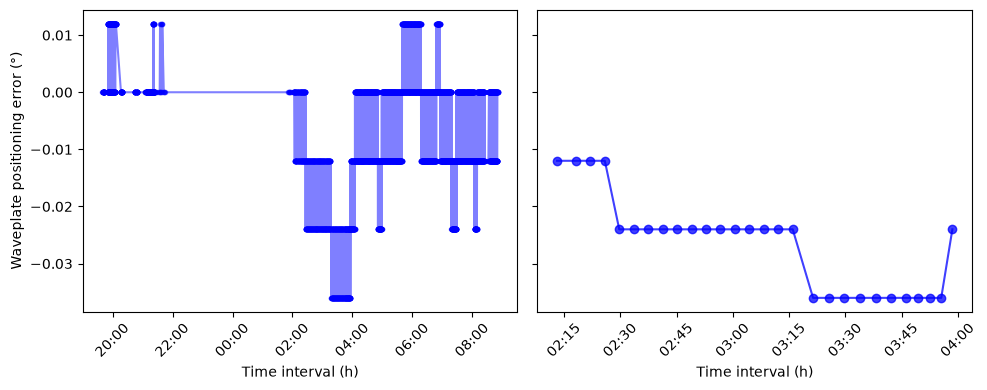

In [7]:
# PLOT THE POSITIONING ERROR VS THE OBSERVATION TIME

import numpy as np
from matplotlib import pyplot as plt
import pandas as pd
from pathlib import Path
from datetime import datetime

fig, axs = plt.subplots(1, 2, sharey=True, figsize=(10, 4))

night = "20260714"
csv_file = Path.cwd() / "_csv" / f"{night}.csv"
df = pd.read_csv(csv_file)
mean, std = np.mean(df["error"]), np.std(df["error"])
df["timestamp"] = pd.to_datetime(df["timestamp"], format="%Y-%m-%dT%H:%M:%S.%f")

ax = axs[0]
ax.plot(df["timestamp"], df["error"], ".-b", alpha=0.5)
ax.set_ylabel("Waveplate positioning error (°)")
ax.set_xlabel("Time interval (h)")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
ax.tick_params(axis="x", labelrotation=45)

df = df[df["seq_idx"] == 16]
df = df[df["frame_idx"] == 1]
df = df[df["timestamp"] > datetime(2026, 7, 15, 1)]
df = df[df["timestamp"] < datetime(2026, 7, 15, 4)]
ax = axs[1]
ax.plot(df["timestamp"], df["error"], "o-b", alpha=0.75)
ax.set_xlabel("Time interval (h)")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
ax.tick_params(axis="x", labelrotation=45)


image_path = Path.cwd() / "_figs" / f"{night}_err_time_series.png"
plt.savefig(image_path, dpi=300, bbox_inches="tight")
image_path = Path(
    rf"C:\Users\Denis\Desktop\NT_WPPOS_ERR\src\XX\Fig\{night}_err_time_series.png"
)
plt.savefig(image_path, dpi=300, bbox_inches="tight")
plt.tight_layout()
plt.show()

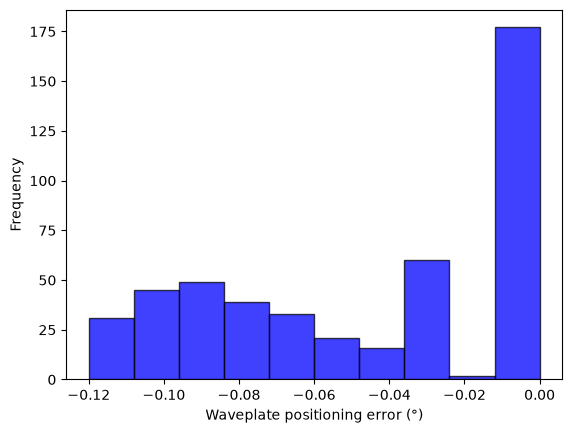

In [ ]:
# PLOT HISTOGRAM DISTRIBUTIONS

import numpy as np
from matplotlib import pyplot as plt
import pandas as pd
from pathlib import Path


night = "20261114"
csv_file = Path.cwd() / "_csv" / f"{night}.csv"
df = pd.read_csv(csv_file)
plt.hist(df["error"], color="blue", edgecolor="black", alpha=0.75)
plt.xlabel("Waveplate positioning error (°)")
plt.ylabel("Frequency")

image_path = Path.cwd() / "_figs" / f"{night}_wppos_error_hist.png"
plt.savefig(image_path, dpi=300, bbox_inches="tight")
image_path = Path(
    rf"C:\Users\Denis\Desktop\NT_WPPOS_ERR\src\XX\Fig\{night}_error_histograms.png"
)
plt.savefig(image_path, dpi=300, bbox_inches="tight")
plt.show()